In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/sample_data/karachi_2024_vehicle_temperature_data.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

In [4]:
def create_features(df):
    df["Hour"] = df.index.hour
    df["DayOfWeek"] = df.index.dayofweek
    df["Month"] = df.index.month
    df["isWeekend"] = df["DayOfWeek"].apply(lambda x: 1 if x >= 5 else 0)
    df["isRushHour"] = df["Hour"].apply(lambda x: 1 if 7 <= x <= 9 or 17 <= x <= 19 else 0)
    # Cyclical encoding for temporal features
    df['hour_sin'] = np.sin(2 * np.pi * df['Hour']/24)
    df['hour_cos'] = np.cos(2 * np.pi * df['Hour']/24)
    df['day_sin'] = np.sin(2 * np.pi * df['DayOfWeek']/7)
    df['day_cos'] = np.cos(2 * np.pi * df['DayOfWeek']/7)
    df['month_sin'] = np.sin(2 * np.pi * (df['Month']-1)/12)
    df['month_cos'] = np.cos(2 * np.pi * (df['Month']-1)/12)

    # Lag features
    df['temp_lag_24h'] = df['Engine_Temperature'].shift(24)
    df['temp_rolling_avg_3d'] = df['Engine_Temperature'].rolling(window=72).mean()

    # Drop original columns and NAs
    df.drop(['Hour', 'DayOfWeek', 'Month'], axis=1, inplace=True)
    df.dropna(inplace=True)
    return df

In [5]:
df = create_features(df)

# Define features and target
features = ['Engine_Temperature', 'isWeekend', 'isRushHour',
            'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
            'month_sin', 'month_cos', 'temp_lag_24h',
            'temp_rolling_avg_3d']
target = 'Engine_Temperature'

In [6]:
train_size = int(len(df) * 0.8)
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

In [7]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_df[features])
test_scaled = scaler.transform(test_df[features])

In [8]:
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data)-window_size-24):  # Predict 24h ahead
        X.append(data[i:i+window_size])
        y.append(data[i+window_size:i+window_size+24, 0])  # Next 24 temperatures
    return np.array(X), np.array(y)

In [9]:
window_size = 168  # 1 week lookback
X_train, y_train = create_sequences(train_scaled, window_size)
X_test, y_test = create_sequences(test_scaled, window_size)

In [10]:
from tensorflow.keras.layers import Bidirectional, BatchNormalization

model = Sequential([
    # Bidirectional LSTM to capture forward/backward patterns
    Bidirectional(LSTM(128, return_sequences=True), input_shape=(window_size, len(features))),
    BatchNormalization(),  # Stabilizes training
    Dropout(0.2),  # Slightly higher dropout for regularization

    # Stacked LSTM with reduced units
    Bidirectional(LSTM(64, return_sequences=True)),
    BatchNormalization(),
    Dropout(0.3),

    # Final LSTM layer
    LSTM(32),

    # Intermediate dense layer for non-linear mapping
    Dense(64, activation='relu'),
    Dropout(0.2),

    # Output layer for 24-hour prediction
    Dense(24)
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

# Define EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the model with early stopping
history = model.fit(X_train, y_train,
                    epochs=50,
                    batch_size=32,
                    validation_split=0.1,
                    verbose=1,
                    callbacks=[early_stopping])

Epoch 1/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - loss: 0.0948 - mae: 0.2296 - val_loss: 0.0134 - val_mae: 0.0958
Epoch 2/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - loss: 0.0149 - mae: 0.0952 - val_loss: 0.0044 - val_mae: 0.0548
Epoch 3/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - loss: 0.0109 - mae: 0.0816 - val_loss: 0.0025 - val_mae: 0.0406
Epoch 4/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - loss: 0.0084 - mae: 0.0711 - val_loss: 0.0029 - val_mae: 0.0429
Epoch 5/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - loss: 0.0074 - mae: 0.0669 - val_loss: 0.0024 - val_mae: 0.0386
Epoch 6/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - loss: 0.0064 - mae: 0.0617 - val_loss: 0.0021 - val_mae: 0.0365
Epoch 7/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - loss: 0.0059 - mae: 0.0594 - val_loss: 0.0022 - val_mae: 0.0374
Epoch 8/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - loss: 0.0054 - mae: 0.0571 - val_loss: 0.0020 - val_mae: 0.0349
Epoch 9/50
191/191 ━━━━━━━━━━━━━━━━━━━━ 1

In [13]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f'Test Loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}')

49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0017 - mae: 0.0315
Test Loss: 0.0018, Test MAE: 0.0322


In [14]:
def inverse_scale_predictions(scaled_predictions, scaler, feature_index=0):
    """
    Inverse scale predictions for multi-step output.

    Args:
        scaled_predictions: Array of shape (n_samples, n_steps)
        scaler: Fitted MinMaxScaler object
        feature_index: Index of the target feature in the original data

    Returns:
        Array of shape (n_samples, n_steps) with inverse-scaled predictions
    """
    # Get the number of samples and steps
    n_samples, n_steps = scaled_predictions.shape

    # Create a dummy array with the same shape as the original data
    dummy = np.zeros((n_samples * n_steps, len(features)))

    # Fill the target feature column with the predictions
    dummy[:, feature_index] = scaled_predictions.flatten()

    # Inverse transform the dummy array
    inverse_scaled = scaler.inverse_transform(dummy)

    # Reshape back to (n_samples, n_steps)
    return inverse_scaled[:, feature_index].reshape(n_samples, n_steps)

In [15]:
# Make predictions
test_predictions = model.predict(X_test[:1])  # Predict first test sample
test_predictions = inverse_scale_predictions(test_predictions, scaler)

# Get the corresponding timestamps for the predictions
prediction_timestamps = test_df.index[window_size:window_size+24]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step


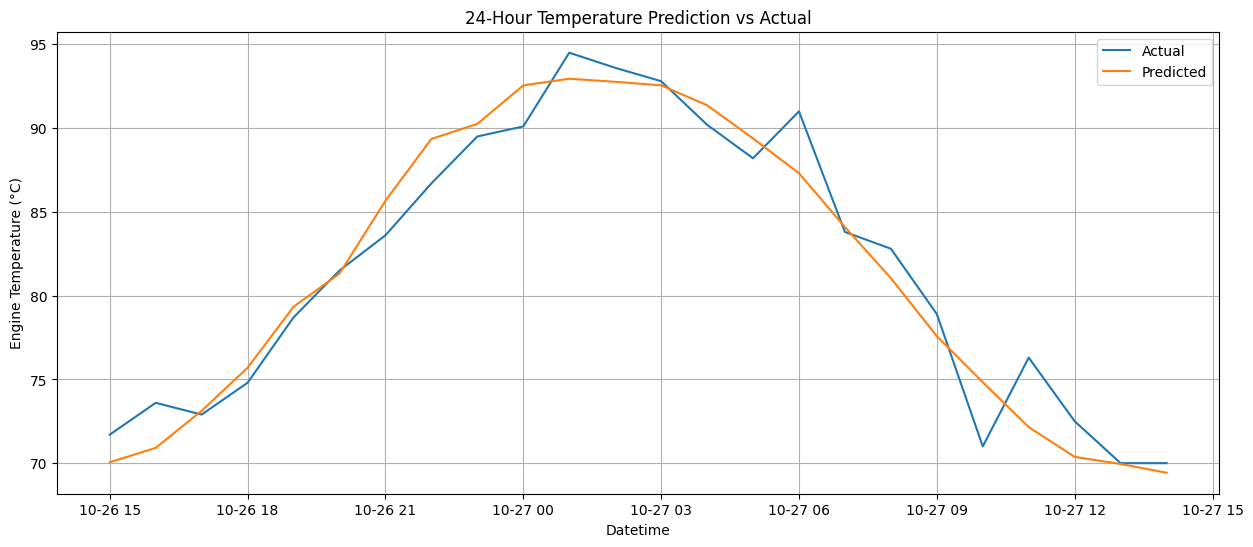

In [16]:
plt.figure(figsize=(15, 6))
plt.plot(test_df.index[window_size:window_size+24], test_df['Engine_Temperature'].iloc[window_size:window_size+24], label='Actual')
plt.plot(test_df.index[window_size:window_size+24], test_predictions.flatten(), label='Predicted')  # Flatten predictions
plt.title('24-Hour Temperature Prediction vs Actual')
plt.xlabel('Datetime')
plt.ylabel('Engine Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()

In [17]:
model.save("Final_Temp_Prediction_Model.h5")

In [19]:
import pickle

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)